<a href="https://colab.research.google.com/github/elizebeth18/Learn-python/blob/main/Python_8_data_visualization_matplotlib_seaborn_Class.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Data Visualization with Matplotlib & Seaborn

In [ ]:
# --- Standard data-science imports ---
import numpy as np                 # numerical arrays and math
import pandas as pd                # tables (DataFrames)
import matplotlib.pyplot as plt    # the plotting engine; 'plt' is the universal nickname
import seaborn as sns
             # statistical plots built on top of matplotlib

# This "magic" line tells Jupyter to draw charts right inside the notebook,
# directly under the cell that created them (instead of a separate window).
#%matplotlib inline

# sns.set_theme() applies Seaborn's clean default styling to *all* charts,
# including plain Matplotlib ones. Call it once at the top.
#sns.set_theme(style="whitegrid")   # a white background with subtle gridlines

#print("Setup complete ✅  — matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__)

# Part 1 — Matplotlib basics

## The anatomy of a plot: Figure vs Axes

This is *the* concept that confuses every beginner, so let's nail it with an analogy.

- A **Figure** is the **whole canvas / picture frame** you hang on the wall. It can hold one drawing or several.
- An **Axes** is a **single drawing** inside that frame — one set of x/y coordinates where data is actually plotted. (Confusingly, "Axes" is one plot, *not* the x-axis and y-axis.)

We create both at once with:

```python
fig, ax = plt.subplots()
```

`fig` is the frame; `ax` is the drawing surface. We then tell `ax` what to draw: `ax.plot(...)`, `ax.bar(...)`, and so on. This is called the **object-oriented style**, and it's the one professionals use because it stays clear when charts get complex.

## 📈 Line plot — showing a trend or change over a sequence

**Use it when:** the x-axis is continuous or ordered (like time, or a range of values) and you want to see how y **moves** across it. Think stock prices over days, or temperature over hours.

In [ ]:
# Create some x values from 0 up to (but not including) 10, stepping by 0.5
x = np.arange(0, 10, 0.5)
y = np.sin(x)                      # y is the sine of each x — a smooth wave

fig, ax = plt.subplots(figsize=(8, 4))   # frame + drawing, 8 inches wide by 4 tall

# Draw the line. Every keyword here is a styling choice:
ax.plot(
    x, y,
    color="teal",       # line colour (name, hex like "#1f77b4", also works)
    linewidth=2,        # thickness of the line
    linestyle="-",      # solid line ("--" dashed, ":" dotted, "-." dash-dot)
    marker="o",         # put a small circle at each data point
    label="sin(x)"      # name used in the legend
)

ax.set_title("A Simple Line Plot")   # title above the chart
ax.set_xlabel("x value")             # label for the horizontal axis
ax.set_ylabel("sin(x)")              # label for the vertical axis
ax.legend()                          # show the box mapping colour -> label

plt.show()   # render the figure. Always call this last.

## 📊 Bar plot — comparing amounts across categories

**Use it when:** the x-axis holds **distinct groups** (categories) and you want to compare a value for each. Think sales per region, or number of passengers per class. The **length** of each bar is what your eye compares.

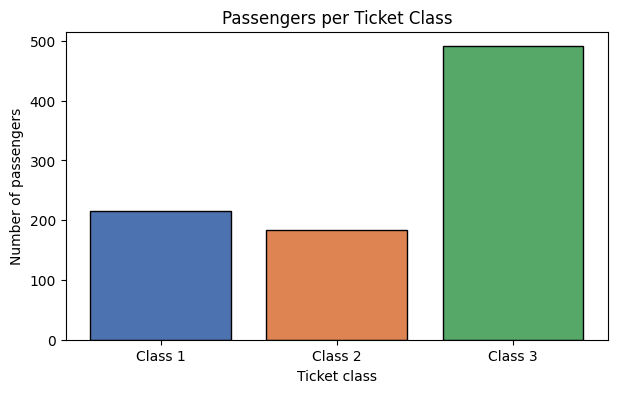

In [ ]:
# Categories on the x-axis, and one numeric value per category
categories = ["Class 1", "Class 2", "Class 3"]
counts     = [216, 184, 491]     # e.g. number of passengers in each class

fig, ax = plt.subplots(figsize=(7, 4))

# A different colour per bar just to show it's possible; usually one colour is cleaner
ax.bar(
    categories, counts,
    color=["#4c72b0", "#dd8452", "#55a868"],  # one colour per bar
    edgecolor="black"                          # thin outline around each bar
)

ax.set_title("Passengers per Ticket Class")
ax.set_xlabel("Ticket class")
ax.set_ylabel("Number of passengers")

# Write the exact value on top of each bar — a nice, professional touch
'''for i, value in enumerate(counts):
    ax.text(i, value + 5, str(value), ha="center")  # ha = horizontal alignment
'''
plt.show()

## 📉 Histogram — showing the *distribution* of one numeric variable

A histogram is **not** a bar chart, even though it looks similar. The difference:

| | Bar chart | Histogram |
|---|---|---|
| X-axis holds | separate **categories** | **ranges (bins)** of one number |
| Bars can be reordered? | yes | no — the order is the number line |
| Answers | "how much per group?" | "how are the values *spread out*?" |

**Use it when:** you have one column of numbers (ages, prices, heights) and you want to see where values cluster — is it centred? skewed? are there outliers? Python slices the range into **bins** and counts how many values fall in each.

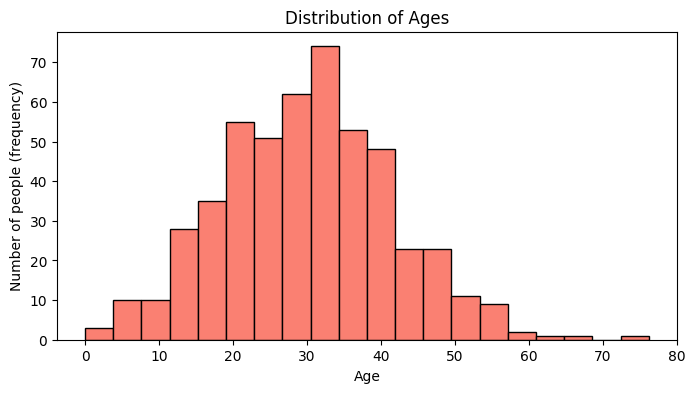

In [ ]:
# Make up 500 ages that cluster around 30 (a "normal" bell-shaped spread)
np.random.seed(42)                          # fixes randomness so results repeat
ages = np.random.normal(loc=30, scale=12, size=500).clip(0, 80)

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    ages,
    bins=20,            # split the age range into 20 equal-width buckets
    color="salmon",
    edgecolor="black"   # outlines make it clear where each bin starts/ends
)

ax.set_title("Distribution of Ages")
ax.set_xlabel("Age")
ax.set_ylabel("Number of people (frequency)")

plt.show()

# ⚠️ 'bins' matters a lot: too few hides the shape, too many makes it noisy.
# Try changing bins=20 to bins=5 and then bins=60 to feel the difference.

## 🔵 Scatter plot — the *relationship* between two numeric variables

**Use it when:** you have **two** numeric columns and want to see if they move together. Each dot is one observation (e.g. one person), placed by its x and y value. Scatter plots reveal **correlation**: do higher x values tend to come with higher y values?

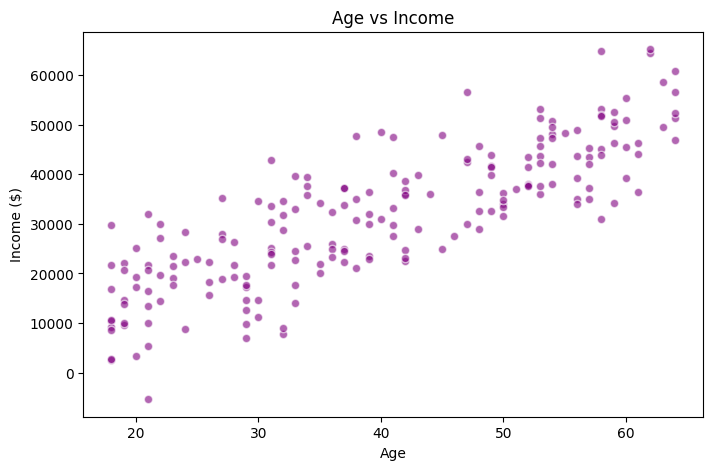

In [ ]:
# Two related numbers: as 'age' goes up, 'income' tends to go up too, plus noise
np.random.seed(0)
age    = np.random.randint(18, 65, 200)
income = age * 800 + np.random.normal(0, 8000, 200)   # trend + random scatter

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    age, income,
    alpha=0.6,        # transparency (0=invisible, 1=solid) — helps see overlaps
    color="purple",
    edgecolor="white"
)

ax.set_title("Age vs Income")
ax.set_xlabel("Age")
ax.set_ylabel("Income ($)")

plt.show()

# Reading it: dots drifting up-and-to-the-right = a positive relationship.

## ✅ Quick recap: which chart, when?

| Chart | Question it answers | X-axis | Y-axis |
|---|---|---|---|
| **Line** | How does a value change across an ordered sequence? | ordered/continuous | numeric |
| **Bar** | How do amounts compare across groups? | categories | numeric |
| **Histogram** | How is a single numeric variable spread out? | value ranges (bins) | count |
| **Scatter** | Are two numeric variables related? | numeric | numeric |

Picking the *wrong* chart is the most common visualization mistake. When in doubt, ask: **"Am I comparing groups, showing a spread, tracking a trend, or relating two numbers?"**

# Part 2 — Styling and customization

A plot that's technically correct but unlabelled is like a paragraph with no punctuation — the reader has to guess. Styling isn't decoration; it's **communication**. This section is your toolbox for making a chart clear and professional.

Here's a single chart that uses many customization options together, all commented.

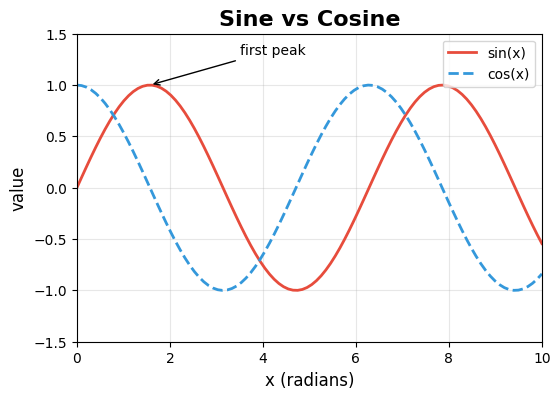

In [ ]:
# Two lines we want to compare on the same axes
x  = np.linspace(0, 10, 100)     # 100 evenly spaced points from 0 to 10
y1 = np.sin(x)
y2 = np.cos(x)

# figsize controls the overall size in inches (width, height)
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(x, y1, color="#e74c3c", linewidth=2, linestyle="-",  label="sin(x)")
ax.plot(x, y2, color="#3498db", linewidth=2, linestyle="--", label="cos(x)")

# --- Text elements ---
ax.set_title("Sine vs Cosine", fontsize=16, fontweight="bold")
ax.set_xlabel("x (radians)", fontsize=12)
ax.set_ylabel("value",       fontsize=12)

# --- Legend: tells the reader which colour is which ---
ax.legend(loc="upper right")     # loc controls placement

# --- Grid and limits ---
ax.grid(True, alpha=0.3)         # faint gridlines to help read values
ax.set_xlim(0, 10)               # force the x-axis range
ax.set_ylim(-1.5, 1.5)           # force the y-axis range

# --- Annotate a specific point of interest ---
ax.annotate("first peak",
            xy=(np.pi/2, 1),                 # point to annotate
            xytext=(3.5, 1.3),               # where the text sits
            arrowprops=dict(arrowstyle="->"))# draw an arrow to the point

plt.show()

## Multiple charts in one figure: subplots

Often you want several charts side by side to compare them. `plt.subplots(nrows, ncols)` returns a grid of Axes. Think of it as **dividing your picture frame into a grid of smaller drawings**.

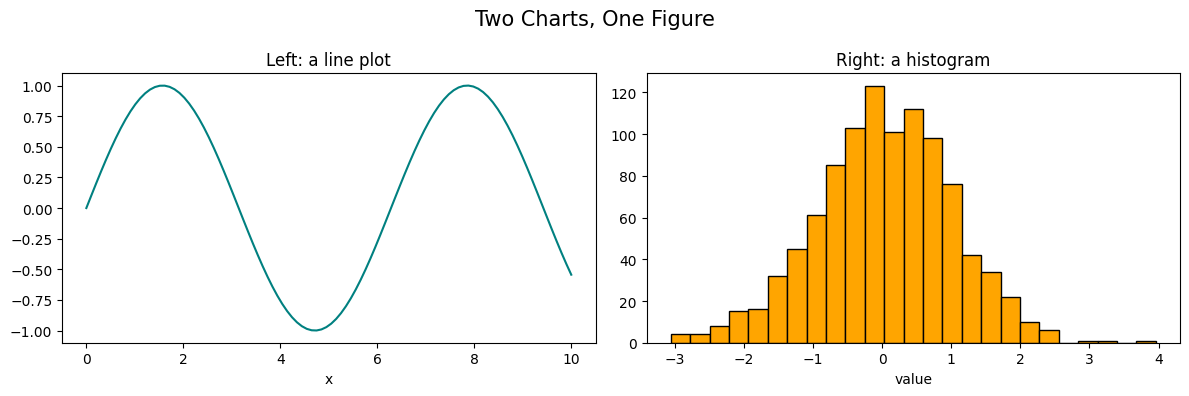

In [ ]:
# A 1-row, 2-column grid of plots. 'axes' is now an array of two Axes objects.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

# --- Left plot: axes[0] ---
axes[0].plot(x, y1, color="teal")
axes[0].set_title("Left: a line plot")
axes[0].set_xlabel("x")

# --- Right plot: axes[1] ---
np.random.seed(1)
axes[1].hist(np.random.normal(0, 1, 1000), bins=25, color="orange", edgecolor="black")
axes[1].set_title("Right: a histogram")
axes[1].set_xlabel("value")

# A title for the whole figure (not just one subplot)
fig.suptitle("Two Charts, One Figure", fontsize=15)

fig.tight_layout()   # automatically fixes overlapping labels/titles — very handy!
plt.show()

## 🎨 Styling cheat-sheet

Keep this handy. These arguments work on most Matplotlib plotting calls:

| Argument | Controls | Example values |
|---|---|---|
| `color` | line/marker colour | `"red"`, `"#3498db"`, `"teal"` |
| `linewidth` / `lw` | line thickness | `1`, `2.5` |
| `linestyle` / `ls` | line pattern | `"-"`, `"--"`, `":"`, `"-."` |
| `marker` | point shape | `"o"`, `"s"` (square), `"^"` (triangle), `"x"` |
| `alpha` | transparency | `0.0`–`1.0` |
| `figsize` | figure size in inches | `(8, 4)` |
| `label` + `.legend()` | series names in a legend | `label="2024 sales"` |

And these methods finish a chart: `set_title()`, `set_xlabel()`, `set_ylabel()`, `legend()`, `grid()`, `set_xlim()`, `set_ylim()`.

# Part 3 — Seaborn for statistical visualization

Everything above was pure Matplotlib. It's powerful but **verbose** — notice how much code a nice chart takes. **Seaborn** sits on top of Matplotlib and gives you gorgeous, statistically-aware charts, usually in **one line**, and it speaks fluent **pandas DataFrame**.

## Matplotlib vs Seaborn — when to reach for which

| | Matplotlib | Seaborn |
|---|---|---|
| **Style** | plain by default | beautiful by default |
| **Input** | arrays / lists | works directly with a DataFrame + column names |
| **Best for** | full manual control, custom charts | fast statistical charts (distributions, categories, correlations) |
| **Code length** | longer | shorter |
| **Relationship** | the engine | a friendly layer *on top* of that engine |

They're **not rivals** — Seaborn *is* Matplotlib underneath, so you can still tweak a Seaborn chart with Matplotlib commands (`plt.title(...)`, etc.). Use Seaborn for the common cases; drop to Matplotlib when you need something bespoke.

For the rest of this part we'll build a small DataFrame to plot from, because Seaborn shines when given a table.

In [ ]:
# Build a small sample DataFrame (a mini "passengers" table) to demonstrate Seaborn.
np.random.seed(7)
n = 300
sample = pd.DataFrame({
    "age":      np.random.normal(30, 12, n).clip(1, 80),
    "fare":     np.random.gamma(2.0, 20, n),          # right-skewed, like real fares
    "pclass":   np.random.choice([1, 2, 3], n, p=[0.25, 0.25, 0.5]),
    "sex":      np.random.choice(["male", "female"], n),
    "survived": np.random.choice([0, 1], n, p=[0.6, 0.4]),
})
sample.head()   # peek at the first 5 rows

,age,fare,pclass,sex,survived
0,50.286308,42.592910,3,male,1
1,24.408752,29.043645,3,male,1
2,30.393842,63.682599,2,male,0
3,34.890195,29.649779,2,male,0
4,20.532924,10.357876,3,male,1


## Distribution with `histplot` — a smarter histogram

Seaborn's `histplot` can overlay a **KDE** (Kernel Density Estimate): a smooth curve estimating the underlying shape of the distribution. Notice we pass the **DataFrame** and just name the **column** — no manual array extraction.

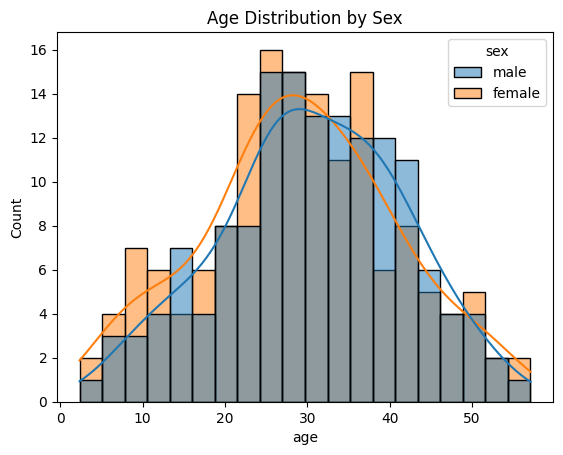

In [ ]:
# One line for a histogram + smooth density curve, coloured by group.
sns.histplot(
    data=sample,     # the DataFrame
    x="age",         # column to plot on the x-axis
    kde=True,        # overlay the smooth density curve
    hue="sex",       # draw a separate colour for each sex
    bins=20
)
plt.title("Age Distribution by Sex")   # we can still use plt for the title
plt.show()

## Categorical charts — `countplot`, `barplot`, `boxplot`

- **`countplot`** counts rows per category (a bar chart of *frequencies*).
- **`barplot`** shows the **average** of a numeric column per category (with a small error bar).
- **`boxplot`** summarises a distribution per category: the box is the middle 50% of values, the line inside is the median, and dots are outliers.

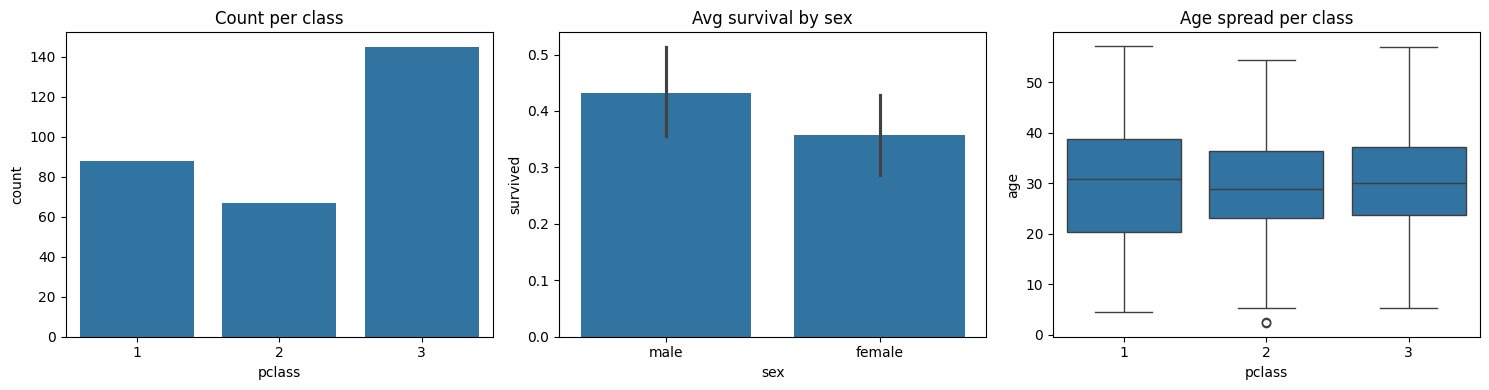

In [ ]:
# Three related charts side by side using subplots + Seaborn's ax= argument
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Count of passengers per class
sns.countplot(data=sample, x="pclass", ax=axes[0])
axes[0].set_title("Count per class")

# Average survival rate per sex (mean of the 0/1 survived column)
sns.barplot(data=sample, x="sex", y="survived", ax=axes[1])
axes[1].set_title("Avg survival by sex")

# Spread of ages within each class
sns.boxplot(data=sample, x="pclass", y="age", ax=axes[2])
axes[2].set_title("Age spread per class")

fig.tight_layout()
plt.show()

## 🔥 Heatmap — visualising a grid of numbers (like a correlation matrix)

A **heatmap** colours a grid of numbers so patterns pop out — bright vs dark instead of reading digits. The classic use is a **correlation matrix**: for every pair of numeric columns, the *correlation* measures how strongly they move together, from **+1** (move together perfectly) through **0** (unrelated) to **−1** (move in opposite directions).

`df.corr()` builds that grid; `sns.heatmap()` paints it.

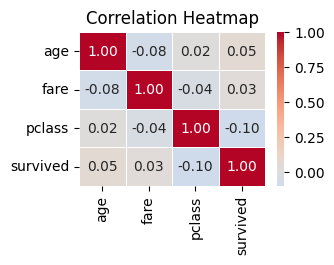

In [ ]:
# Compute correlations between all numeric columns.
# numeric_only=True safely skips text columns like 'sex'.
corr = sample.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(3,2))
sns.heatmap(
    corr,
    annot=True,        # write the actual number in each cell
    fmt=".2f",         # format numbers to 2 decimal places
    cmap="coolwarm",   # blue = negative, red = positive correlation
    center=0,          # anchor the colour scale so 0 is neutral
    linewidths=0.5,    # thin lines between cells
    ax=ax
)
ax.set_title("Correlation Heatmap")
plt.show()

# How to read it: find a cell, note its colour (red=positive, blue=negative)
# and its number. The diagonal is always 1.0 (every column with itself).

## 🧩 Pairplot — every relationship at a glance

A **pairplot** is a grid showing a scatter plot for **every pair** of numeric columns, with each column's histogram down the diagonal. It's the fastest way to eyeball an entire dataset. It can be slow on big/wide data, so it's best on a handful of numeric columns — the famous **Iris** flower dataset is the textbook example.

> ℹ️ `sns.load_dataset("iris")` downloads a tiny built-in dataset from Seaborn's online repository the first time you run it, so you'll need an **internet connection**. After that it's cached locally.

In [ ]:
# Load the classic Iris dataset (150 flowers, 4 measurements, 3 species)
iris = sns.load_dataset("iris")
print(iris.shape)     # (150, 5)
iris.head()

(150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


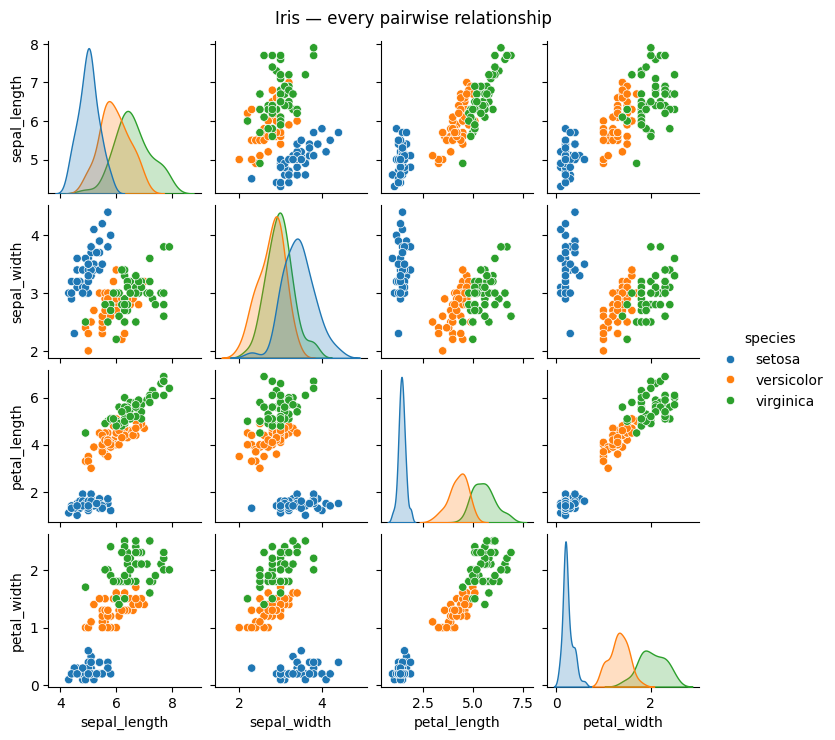

In [ ]:
# One line draws 16 little charts! hue colours each point by flower species.
sns.pairplot(iris, hue="species", height=1.8)
plt.suptitle("Iris — every pairwise relationship", y=1.02)
plt.show()

# Notice how one species (setosa) separates cleanly from the others in petal
# measurements — a pattern that's obvious visually but tedious to spot in numbers.

# Hands-On: EDA on the Titanic dataset

Time to put it all together on **real data**. **Exploratory Data Analysis (EDA)** is the detective phase of any data project: before building anything fancy, you *look* at your data to understand its shape, spot problems (missing values, weird outliers), and find the stories worth telling.

Our workflow:

1. **Load** the data and take a first look (`head`, `info`, `describe`).
2. **Check quality** — how many values are missing?
3. **Ask questions** and answer each with a **meaningful plot**.
4. **Summarise** the findings in plain English.

> ℹ️ `sns.load_dataset("titanic")` downloads the dataset from Seaborn's online repo the first time, so an **internet connection** is needed once. It's then cached.

In [ ]:
# 1) Load the Titanic dataset — 891 passengers with survival info
titanic = sns.load_dataset("titanic")

print("Shape (rows, columns):", titanic.shape)
titanic.head()     # first 5 rows

Shape (rows, columns): (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
# .info() lists every column, its data type, and how many non-null values it has.
# This is the quickest way to spot missing data and text-vs-number columns.
titanic.info()

In [ ]:
# .describe() gives summary statistics (count, mean, min, max, quartiles)
# for the numeric columns — a fast feel for typical values and ranges.
titanic.describe()

In [ ]:
# 2) Check missing values: sum of NaNs per column, biggest offenders first.
missing = titanic.isnull().sum().sort_values(ascending=False)
print("Missing values per column:\n")
print(missing[missing > 0])

# Takeaway: 'deck' is mostly empty, 'age' has a chunk missing, 'embarked' a few.
# In real work you'd decide to fill or drop these; for EDA we just stay aware.

### 🔎 Our EDA questions

Let's investigate three questions, each with one clear chart:

1. **Did survival depend on sex?**
2. **How were passengers' ages distributed, and did age relate to survival?**
3. **Did ticket class relate to the fare paid — and to survival?**

#### Plot 1 — Survival rate by sex

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

# barplot shows the MEAN of 'survived' (a 0/1 column) per sex = survival RATE
sns.barplot(data=titanic, x="sex", y="survived", ax=ax)

ax.set_title("Survival Rate by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Proportion who survived")
ax.set_ylim(0, 1)

plt.show()

**📌 Finding 1:** Females survived at roughly **74%**, males at only about **19%**. The "women and children first" evacuation policy shows up dramatically in the data — sex is one of the strongest predictors of survival on the Titanic.

#### Plot 2 — Age distribution, split by survival

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))

# Overlaid histograms: one for those who died, one for survivors.
sns.histplot(
    data=titanic,
    x="age",
    hue="survived",     # separate colour per survival outcome
    bins=30,
    kde=True,           # smooth density curve on top
    ax=ax
)
ax.set_title("Age Distribution by Survival")
ax.set_xlabel("Age")
ax.set_ylabel("Number of passengers")

plt.show()

**📌 Finding 2:** Most passengers were young adults (20–40). Very **young children** show a visibly higher survival share than other age groups — again consistent with "children first." Age alone is a weaker signal than sex, but the youngest passengers clearly benefited.

#### Plot 3 — Fare by class, coloured by survival

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

# boxplot shows the fare distribution within each class;
# hue splits each box by survival so we can compare within a class.
sns.boxplot(data=titanic, x="pclass", y="fare", hue="survived", ax=ax)

ax.set_title("Fare by Passenger Class and Survival")
ax.set_xlabel("Passenger class (1 = first)")
ax.set_ylabel("Fare paid")
ax.set_ylim(0, 300)     # clip extreme outliers so the boxes are readable

plt.show()

**📌 Finding 3:** First-class passengers paid far higher fares — and survived at a higher rate — than third-class passengers. Wealth and class were tied to being on the upper decks (closer to lifeboats), so **class is a strong survival predictor too.**

### 📝 Summary of findings

From three plots we've extracted the core story of the Titanic disaster:

1. **Sex mattered most:** ~74% of women survived vs ~19% of men.
2. **Age mattered a little:** young children were more likely to survive; otherwise age was a weak signal.
3. **Class/wealth mattered:** first-class passengers paid more and survived more often than third-class passengers.

Together these paint a clear picture: **survival was strongly shaped by *who you were* (sex, age) and *what you could afford* (class)** — not by chance alone. That's the power of EDA: a handful of well-chosen charts turned 891 rows of raw data into an understandable narrative.

# 🎓 Assignments

Complete all five. They rise from **beginner** to **challenge**. Each stub has commented-out test cases and the expected output — uncomment and run them to check your work.

**Setup for the assignments** — run this cell first:

In [ ]:
# Datasets you'll use in the assignments (needs internet the first time)
iris    = sns.load_dataset("iris")
titanic = sns.load_dataset("titanic")
tips    = sns.load_dataset("tips")     # restaurant bills & tips — 244 rows

print("iris   :", iris.shape)
print("titanic:", titanic.shape)
print("tips   :", tips.shape)

### Assignment 1 — Beginner: a labelled bar chart

Using the `tips` dataset, draw a **bar chart** of the **average total bill for each day** (`day` on the x-axis, `total_bill` on the y-axis). Give it a **title**, an **x-label**, and a **y-label**.

*Hint:* `sns.barplot(data=..., x=..., y=...)` computes the average automatically.

In [ ]:
# --- Your code here ---
def plot_avg_bill_by_day():
    fig, ax = plt.subplots(figsize=(7, 4))
    # TODO: draw a barplot of average total_bill per day
    # TODO: set title, xlabel, ylabel
    plt.show()

# plot_avg_bill_by_day()
#
# Expected output: a bar chart with 4 bars (Thur, Fri, Sat, Sun),
# a clear title, and both axes labelled. Sat/Sun bars are the tallest.

### Assignment 2 — Beginner/Intermediate: a histogram of ages

Using the `titanic` dataset, draw a **histogram** of the `age` column with **25 bins** and black bar edges. Title it and label both axes.

*Hint:* drop missing ages first with `titanic["age"].dropna()`.

In [ ]:
# --- Your code here ---
def plot_age_histogram():
    fig, ax = plt.subplots(figsize=(8, 4))
    # TODO: histogram of titanic ages (dropna), bins=25, edgecolor="black"
    # TODO: title + axis labels
    plt.show()

# plot_age_histogram()
#
# Expected output: a histogram peaking around ages 20-30, right-skewed,
# 25 bins, with a title and labelled x ('Age') and y ('Frequency') axes.

### Assignment 3 — Intermediate: a scatter plot with a hue

Using the `tips` dataset, make a **scatter plot** of `total_bill` (x) vs `tip` (y), colouring the points by `time` (Lunch vs Dinner). Add a title and axis labels.

*Hint:* `sns.scatterplot(data=..., x=..., y=..., hue=...)`.

In [ ]:
# --- Your code here ---
def plot_bill_vs_tip():
    fig, ax = plt.subplots(figsize=(8, 5))
    # TODO: scatterplot of total_bill vs tip, hue="time"
    # TODO: title + axis labels
    plt.show()

# plot_bill_vs_tip()
#
# Expected output: an upward-drifting cloud of points (bigger bills -> bigger
# tips), points coloured by Lunch/Dinner, with a legend, title, and labels.

### Assignment 4 — Intermediate/Advanced: a correlation heatmap

Using the `iris` dataset, compute the correlation matrix of its **numeric** columns and draw a **heatmap** with the numbers annotated (2 decimals) and the `"coolwarm"` colour map. Add a title.

*Hint:* `iris.corr(numeric_only=True)`, then `sns.heatmap(..., annot=True, fmt=".2f", cmap="coolwarm")`.

In [ ]:
# --- Your code here ---
def plot_iris_heatmap():
    corr = None   # TODO: compute iris.corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(6, 5))
    # TODO: sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
    # TODO: title
    plt.show()

# plot_iris_heatmap()
#
# Expected output: a 4x4 heatmap. petal_length & petal_width should show a
# very strong positive correlation (~0.96), sepal_width the weakest links.

### Assignment 5 — 🔥 Challenge: a 2×2 EDA dashboard

Using the `titanic` dataset, build **one figure with four subplots** (2 rows × 2 columns) that together summarise the dataset:

1. **Top-left:** countplot of survivors vs non-survivors (`x="survived"`).
2. **Top-right:** barplot of survival rate by `pclass`.
3. **Bottom-left:** boxplot of `age` by `pclass`.
4. **Bottom-right:** countplot of passengers per `embark_town`.

Every subplot must have its **own title**. Use `fig.suptitle(...)` for an overall title and `fig.tight_layout()` so nothing overlaps.

*Hint:* pass each Seaborn call `ax=axes[row][col]`.

In [ ]:
# --- Your code here ---
def titanic_dashboard():
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    # TODO 1: sns.countplot(data=titanic, x="survived", ax=axes[0][0])
    #         axes[0][0].set_title(...)

    # TODO 2: sns.barplot(data=titanic, x="pclass", y="survived", ax=axes[0][1])
    #         axes[0][1].set_title(...)

    # TODO 3: sns.boxplot(data=titanic, x="pclass", y="age", ax=axes[1][0])
    #         axes[1][0].set_title(...)

    # TODO 4: sns.countplot(data=titanic, x="embark_town", ax=axes[1][1])
    #         axes[1][1].set_title(...)

    fig.suptitle("Titanic EDA Dashboard", fontsize=16)
    fig.tight_layout()
    plt.show()

# titanic_dashboard()
#
# Expected output: a single figure with 4 titled subplots arranged 2x2,
# an overall figure title, and no overlapping labels. This is a mini version
# of a real analyst's "first look" dashboard.